In [72]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import matplotlib.pyplot as plt

import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

pio.templates.default = "plotly_white"

In [73]:
amazon_data = pd.read_csv("amazon.csv")
amazon_data

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1460,B08L7J3T31,Noir Aqua - 5pcs PP Spun Filter + 1 Spanner | ...,Home&Kitchen|Kitchen&HomeAppliances|WaterPurif...,₹379,₹919,59%,4,"1,090",SUPREME QUALITY 90 GRAM 3 LAYER THIK PP SPUN F...,"AHITFY6AHALOFOHOZEOC6XBP4FEA,AFRABBODZJZQB6Z4U...","Prabha ds,Raghuram bk,Real Deal,Amazon Custome...","R3G3XFHPBFF0E8,R3C0BZCD32EIGW,R2EBVBCN9QPD9R,R...","Received the product without spanner,Excellent...","I received product without spanner,Excellent p...",https://m.media-amazon.com/images/I/41fDdRtjfx...,https://www.amazon.in/Noir-Aqua-Spanner-Purifi...
1461,B01M6453MB,Prestige Delight PRWO Electric Rice Cooker (1 ...,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,"₹2,280","₹3,045",25%,4.1,"4,118","230 Volts, 400 watts, 1 Year","AFG5FM3NEMOL6BNFRV2NK5FNJCHQ,AGEINTRN6Z563RMLH...","Manu Bhai,Naveenpittu,Evatira Sangma,JAGANNADH...","R3DDL2UPKQ2CK9,R2SYYU1OATVIU5,R1VM993161IYRW,R...","ok,everything was good couldn't return bcoz I ...","ok,got everything as mentioned but the me

In [74]:
amazon_data.drop("user_id" , axis=1 , inplace=True)
amazon_data

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1460,B08L7J3T31,Noir Aqua - 5pcs PP Spun Filter + 1 Spanner | ...,Home&Kitchen|Kitchen&HomeAppliances|WaterPurif...,₹379,₹919,59%,4,"1,090",SUPREME QUALITY 90 GRAM 3 LAYER THIK PP SPUN F...,"Prabha ds,Raghuram bk,Real Deal,Amazon Custome...","R3G3XFHPBFF0E8,R3C0BZCD32EIGW,R2EBVBCN9QPD9R,R...","Received the product without spanner,Excellent...","I received product without spanner,Excellent p...",https://m.media-amazon.com/images/I/41fDdRtjfx...,https://www.amazon.in/Noir-Aqua-Spanner-Purifi...
1461,B01M6453MB,Prestige Delight PRWO Electric Rice Cooker (1 ...,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,"₹2,280","₹3,045",25%,4.1,"4,118","230 Volts, 400 watts, 1 Year","Manu Bhai,Naveenpittu,Evatira Sangma,JAGANNADH...","R3DDL2UPKQ2CK9,R2SYYU1OATVIU5,R1VM993161IYRW,R...","ok,everything was good couldn't return bcoz I ...","ok,got everything as mentioned but the measuri...",https://m.media-amazon.com/images/I/41gzDxk4+k...,https://www.amazon.in/Prestige-Delight-PRWO-1-...
1462,B009P2LIL4,Bajaj Majesty RX10 2000 Watts Heat Convector R...,"Home&Kitchen|Heating,Cooling&AirQuality|RoomHe...","₹2,219","₹3,080",28%,3.6,468,International design and styling|Two heat sett...,"Nehal Desai,Danish Parwez,Amazon Customer,Amaz...","R1TLRJVW4STY5I,

In [75]:
amazon_data.drop("user_name" , axis=1 , inplace=True)
amazon_data

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1460,B08L7J3T31,Noir Aqua - 5pcs PP Spun Filter + 1 Spanner | ...,Home&Kitchen|Kitchen&HomeAppliances|WaterPurif...,₹379,₹919,59%,4,"1,090",SUPREME QUALITY 90 GRAM 3 LAYER THIK PP SPUN F...,"R3G3XFHPBFF0E8,R3C0BZCD32EIGW,R2EBVBCN9QPD9R,R...","Received the product without spanner,Excellent...","I received product without spanner,Excellent p...",https://m.media-amazon.com/images/I/41fDdRtjfx...,https://www.amazon.in/Noir-Aqua-Spanner-Purifi...
1461,B01M6453MB,Prestige Delight PRWO Electric Rice Cooker (1 ...,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,"₹2,280","₹3,045",25%,4.1,"4,118","230 Volts, 400 watts, 1 Year","R3DDL2UPKQ2CK9,R2SYYU1OATVIU5,R1VM993161IYRW,R...","ok,everything was good couldn't return bcoz I ...","ok,got everything as mentioned but the measuri...",https://m.media-amazon.com/images/I/41gzDxk4+k...,https://www.amazon.in/Prestige-Delight-PRWO-1-...
1462,B009P2LIL4,Bajaj Majesty RX10 2000 Watts Heat Convector R...,"Home&Kitchen|Heating,Cooling&AirQuality|RoomHe...","₹2,219","₹3,080",28%,3.6,468,International design and styling|Two heat sett...,"R1TLRJVW4STY5I,R2O455KRN493R1,R3Q5MVGBRIAS2G,R...","very good,Work but front melt after 2 month,Go...","plastic but cool body ,u have to find sturdy s...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Bajaj-RX-10-2000-Watt-Co...
1463,B00J5DYCCA,Havells Ventil Air DSP 230mm Exhaust Fan (Pist...,"Home&Kitchen|Heating,Cooling&AirQuality|Fans|E...","₹1,399","₹1,890",26%,4,"8,031",Fan sweep area: 230 MM ; Noise level: (4

In [76]:
def handelPercentage(value):
    value = str(value).split('%')
    value = value[0];
    return float(value)

amazon_data['discount_percentage'] = amazon_data['discount_percentage'].apply(handelPercentage)
amazon_data
    

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64.0,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43.0,4.0,"43,994","Compatible with all Type C enabled devices, be...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90.0,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53.0,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61.0,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1460,B08L7J3T31,Noir Aqua - 5pcs PP Spun Filter + 1 Spanner | ...,Home&Kitchen|Kitchen&HomeAppliances|WaterPurif...,₹379,₹919,59.0,4,"1,090",SUPREME QUALITY 90 GRAM 3 LAYER THIK PP SPUN F...,"R3G3XFHPBFF0E8,R3C0BZCD32EIGW,R2EBVBCN9QPD9R,R...","Received the product without spanner,Excellent...","I received product without spanner,Excellent p...",https://m.media-amazon.com/images/I/41fDdRtjfx...,https://www.amazon.in/Noir-Aqua-Spanner-Purifi...
1461,B01M6453MB,Prestige Delight PRWO Electric Rice Cooker (1 ...,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,"₹2,280","₹3,045",25.0,4.1,"4,118","230 Volts, 400 watts, 1 Year","R3DDL2UPKQ2CK9,R2SYYU1OATVIU5,R1VM993161IYRW,R...","ok,everything was good couldn't return bcoz I ...","ok,got everything as mentioned but the measuri...",https://m.media-amazon.com/images/I/41gzDxk4+k...,https://www.amazon.in/Prestige-Delight-PRWO-1-...
1462,B009P2LIL4,Bajaj Majesty RX10 2000 Watts Heat Convector R...,"Home&Kitchen|Heating,Cooling&AirQuality|RoomHe...","₹2,219","₹3,080",28.0,3.6,468,International design and styling|Two heat sett...,"R1TLRJVW4STY5I,R2O455KRN493R1,R3Q5MVGBRIAS2G,R...","very good,Work but front melt after 2 month,Go...","plastic but cool body ,u have to find sturdy s...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Bajaj-RX-10-2000-Watt-Co...
1463,B00J5DYCCA,Havells Ventil Air DSP 230mm Exhaust Fan (Pist...,"Home&Kitchen|Heating,Cooling&AirQuality|Fans|E...","₹1,399","₹1,890",26.0,4,"8,031",Fan sweep area: 230 MM ; Noise 

In [77]:
def clean_price(amazon_data , value):

   amazon_data[value] = (amazon_data[value].str.replace("₹" , "", regex=False)
                      .str.replace("," ,"", regex=False)
                      .astype(float))
   return amazon_data

amazon_data = clean_price(amazon_data , "discounted_price")
amazon_data = clean_price(amazon_data , "actual_price")

amazon_data.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64.0,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43.0,4.0,"43,994","Compatible with all Type C enabled devices, be...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,90.0,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,53.0,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,61.0,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [78]:
amazon_data

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64.0,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43.0,4.0,"43,994","Compatible with all Type C enabled devices, be...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,90.0,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,53.0,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,61.0,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1460,B08L7J3T31,Noir Aqua - 5pcs PP Spun Filter + 1 Spanner | ...,Home&Kitchen|Kitchen&HomeAppliances|WaterPurif...,379.0,919.0,59.0,4,"1,090",SUPREME QUALITY 90 GRAM 3 LAYER THIK PP SPUN F...,"R3G3XFHPBFF0E8,R3C0BZCD32EIGW,R2EBVBCN9QPD9R,R...","Received the product without spanner,Excellent...","I received product without spanner,Excellent p...",https://m.media-amazon.com/images/I/41fDdRtjfx...,https://www.amazon.in/Noir-Aqua-Spanner-Purifi...
1461,B01M6453MB,Prestige Delight PRWO Electric Rice Cooker (1 ...,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,2280.0,3045.0,25.0,4.1,"4,118","230 Volts, 400 watts, 1 Year","R3DDL2UPKQ2CK9,R2SYYU1OATVIU5,R1VM993161IYRW,R...","ok,everything was good couldn't return bcoz I ...","ok,got everything as mentioned but the measuri...",https://m.media-amazon.com/images/I/41gzDxk4+k...,https://www.amazon.in/Prestige-Delight-PRWO-1-...
1462,B009P2LIL4,Bajaj Majesty RX10 2000 Watts Heat Convector R...,"Home&Kitchen|Heating,Cooling&AirQuality|RoomHe...",2219.0,3080.0,28.0,3.6,468,International design and styling|Two heat sett...,"R1TLRJVW4STY5I,R2O455KRN493R1,R3Q5MVGBRIAS2G,R...","very good,Work but front melt after 2 month,Go...","plastic but cool body ,u have to find sturdy s...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Bajaj-RX-10-2000-Watt-Co...
1463,B00J5DYCCA,Havells Ventil Air DSP 230mm Exhaust Fan (Pist...,"Home&Kitchen|Heating,Cooling&AirQuality|Fans|E...",1399.0,1890.0,26.0,4,"8,031",Fan sweep area: 230 MM ; Noise level:

In [79]:
amazon_data.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64.0,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43.0,4.0,"43,994","Compatible with all Type C enabled devices, be...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,90.0,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,53.0,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,61.0,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [80]:
amazon_data['rating_count'] = (
    amazon_data['rating_count']
    .str.replace(',', '', regex=False)
    .astype(float)
)



# Rating ko str se float mein convert kiya

In [81]:
amazon_data.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64.0,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,"R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43.0,4.0,43994.0,"Compatible with all Type C enabled devices, be...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,90.0,3.9,7928.0,【 Fast Charger& Data Sync】-With built-in safet...,"R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,53.0,4.2,94363.0,The boAt Deuce USB 300 2 in 1 cable is compati...,"R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,61.0,4.2,16905.0,[CHARGE & SYNC FUNCTION]- This cable comes wit...,"R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [82]:
amazon_data[['actual_price',
             'discounted_price',
             'discount_percentage',
             'rating']].dtypes

actual_price           float64
discounted_price       float64
discount_percentage    float64
rating                     str
dtype: object

In [83]:
amazon_data['rating'] = pd.to_numeric(
    amazon_data['rating'],
    errors='coerce'
)

In [84]:
amazon_data.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64.0,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,"R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43.0,4.0,43994.0,"Compatible with all Type C enabled devices, be...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,90.0,3.9,7928.0,【 Fast Charger& Data Sync】-With built-in safet...,"R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,53.0,4.2,94363.0,The boAt Deuce USB 300 2 in 1 cable is compati...,"R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,61.0,4.2,16905.0,[CHARGE & SYNC FUNCTION]- This cable comes wit...,"R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [85]:
amazon_data[['actual_price',
             'discounted_price',
             'discount_percentage',
             'rating']].dtypes

actual_price           float64
discounted_price       float64
discount_percentage    float64
rating                 float64
dtype: object

In [86]:
amazon_data.groupby('category').agg({
    'actual_price': 'mean',
    'discounted_price': 'mean',
    'discount_percentage': 'mean',
    'rating': 'mean'
})

,actual_price,discounted_price,discount_percentage,rating
category,,,,
Car&Motorbike|CarAccessories|InteriorAccessories|AirPurifiers&Ionizers,4000.000000,2339.000000,42.0,3.800000
Computers&Accessories|Accessories&Peripherals|Adapters|USBtoUSBAdapters,2699.000000,221.500000,78.5,4.150000
Computers&Accessories|Accessories&Peripherals|Audio&VideoAccessories|PCHeadsets,999.000000,649.000000,35.0,3.500000
Computers&Accessories|Accessories&Peripherals|Audio&VideoAccessories|PCMicrophones,1249.500000,574.000000,56.5,3.600000
Computers&Accessories|Accessories&Peripherals|Audio&VideoAccessories|PCSpeakers,1399.500000,749.000000,46.5,4.050000
...,...,...,...,...
"OfficeProducts|OfficePaperProducts|Paper|Stationery|Pens,Pencils&WritingSupplies|Pens&Refills|GelInkRollerballPens",150.000000,150.000000,0.0,4.250000
"OfficeProducts|OfficePaperProducts|Paper|Stationery|Pens,Pencils&WritingSupplies|Pens&Refills|LiquidInkRollerballPens",260.000000,255.000000,5.0,4.150000
"OfficeProducts|OfficePaperProducts|Paper|Stationery|Pens,Pencils&WritingSupplies|Pens&Refills|RetractableBallpointPens",405.000000,329.000000,17.5,4.300000


In [87]:
amazon_data['main_category'] = amazon_data['category'].str.split('|').str[0]

In [88]:
amazon_data['main_category'].value_counts()

main_category
Electronics              526
Computers&Accessories    453
Home&Kitchen             448
OfficeProducts            31
MusicalInstruments         2
HomeImprovement            2
Toys&Games                 1
Car&Motorbike              1
Health&PersonalCare        1
Name: count, dtype: int64

# Electronics mein sabse jyada products hai
# Toy&Games , Car&Motorbikes and Health&PersonalCare categories have less products
 

In [89]:
amazon_data.groupby('main_category').agg({
    'actual_price': 'mean',
    'discounted_price': 'mean',
    'discount_percentage': 'mean',
    'rating': 'mean',
    'rating_count' : 'mean'
})

,actual_price,discounted_price,discount_percentage,rating,rating_count
main_category,,,,,
Car&Motorbike,4000.000000,2339.000000,42.000000,3.800000,1118.000000
Computers&Accessories,1683.623135,842.650375,54.024283,4.154967,17136.782705
Electronics,10127.311787,5965.887833,50.828897,4.081749,29997.809886
Health&PersonalCare,1900.000000,899.000000,53.000000,4.000000,3663.000000
Home&Kitchen,4162.073661,2330.615647,40.120536,4.040716,6676.493304
HomeImprovement,799.000000,337.000000,57.500000,4.250000,4283.000000
MusicalInstruments,1347.000000,638.000000,46.000000,3.900000,44441.000000
OfficeProducts,397.193548,301.580645,12.354839,4.309677,4828.225806
Toys&Games,150.000000,150.000000,0.000000,4.300000,15867.000000


# Insights 

#  Average Actual price of Electronis category is more than any other categories
# Toy&games category have Lowest average actual price 
# Average Discounted price of Electronics category also more than any other categories
# Toy&games category have Lowest average discounted price
# Average Discount percentage on HomeImprovement is more than other category
# Toy&games category have Lowest average discounted percentage
# Office product have more highest average rating i.e. 4.31
# Cr&Motorbike had lowest average rating
# Average rating count of musicalInstrument is highest
# Average rating count of Car&Motorbikes  is lowest

In [95]:
amazon_data.groupby('main_category')['actual_price'].mean()

main_category
Car&Motorbike             4000.000000
Computers&Accessories     1683.623135
Electronics              10127.311787
Health&PersonalCare       1900.000000
Home&Kitchen              4162.073661
HomeImprovement            799.000000
MusicalInstruments        1347.000000
OfficeProducts             397.193548
Toys&Games                 150.000000
Name: actual_price, dtype: float64

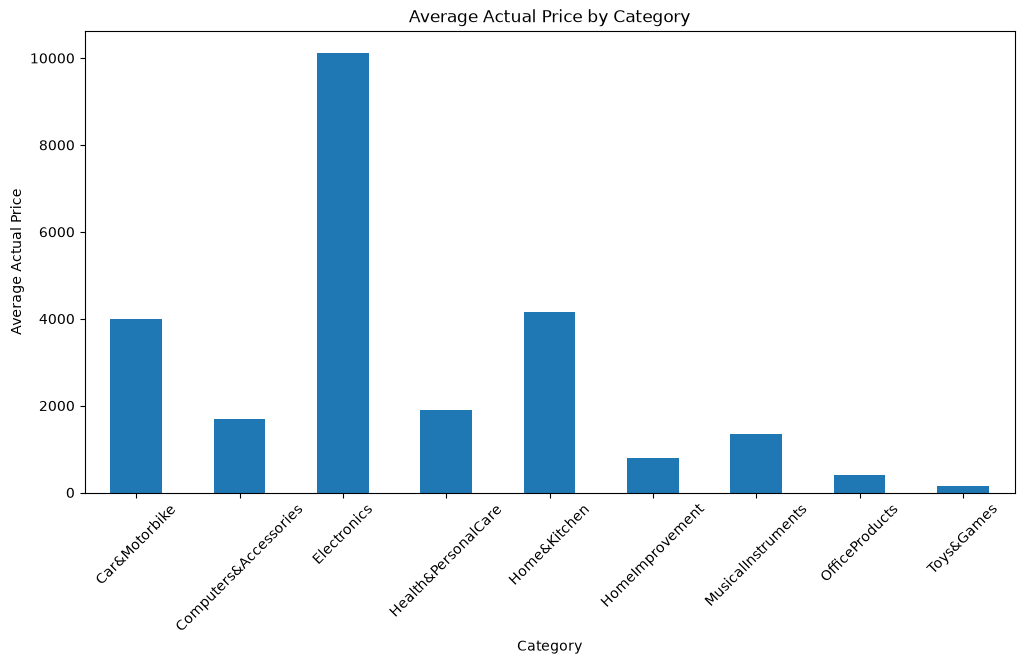

In [69]:
result = amazon_data.groupby('main_category')['actual_price'].mean()

result.plot(kind='bar', figsize=(12,6))

plt.title('Average Actual Price by Category')
plt.xlabel('Category')
plt.ylabel('Average Actual Price')
plt.xticks(rotation=45)
plt.show()

In [96]:
amazon_data.groupby('main_category')['discounted_price'].mean()

main_category
Car&Motorbike            2339.000000
Computers&Accessories     842.650375
Electronics              5965.887833
Health&PersonalCare       899.000000
Home&Kitchen             2330.615647
HomeImprovement           337.000000
MusicalInstruments        638.000000
OfficeProducts            301.580645
Toys&Games                150.000000
Name: discounted_price, dtype: float64

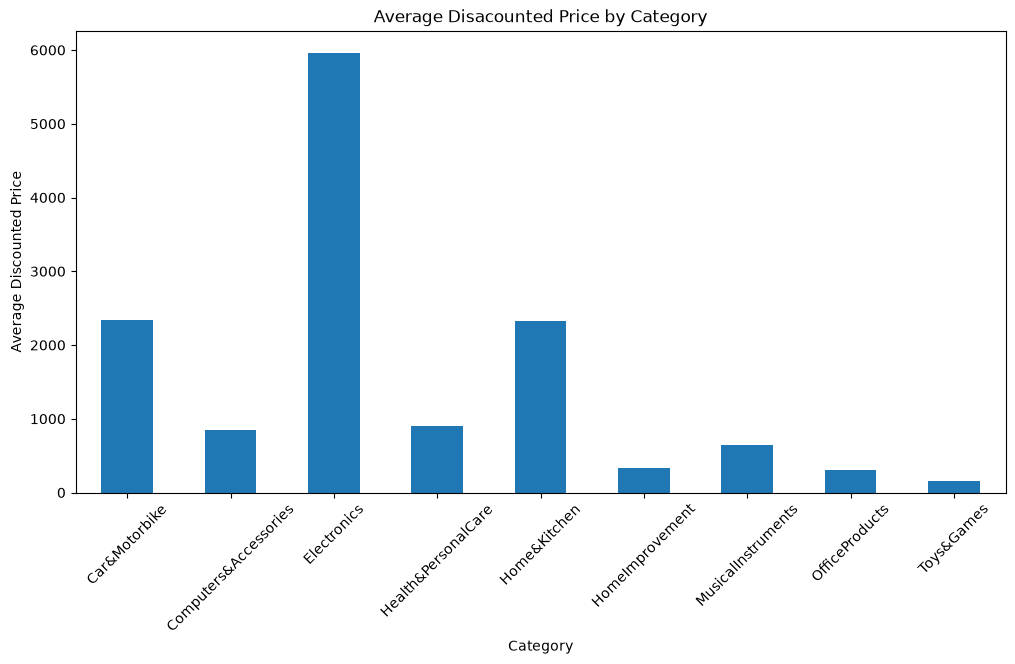

In [98]:
result = amazon_data.groupby('main_category')['discounted_price'].mean()

result.plot(kind='bar', figsize=(12,6))

plt.title('Average Disacounted Price by Category')
plt.xlabel('Category')
plt.ylabel('Average Discounted Price')
plt.xticks(rotation=45)
plt.show()

In [101]:
price_comparison = amazon_data.groupby('main_category')[[
    'actual_price',
    'discounted_price'
]].mean()

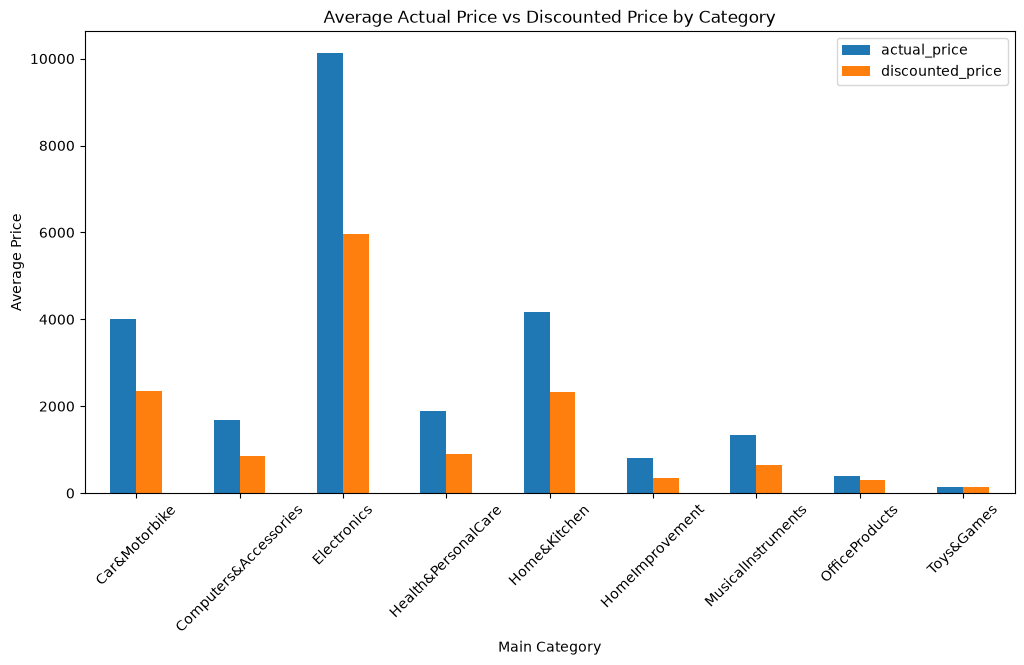

In [102]:
price_comparison.plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Average Actual Price vs Discounted Price by Category')
plt.xlabel('Main Category')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.show()

# Average Discounted price of Electronics is also more than Average Actual price of other category product
# Average Actual price of Toys&Games is less than Discounted price of any other category product

In [107]:
price_comparison = amazon_data.groupby('main_category')[[
    'actual_price',
    'discounted_price',
    
    'rating_count',
   
    
]].mean()

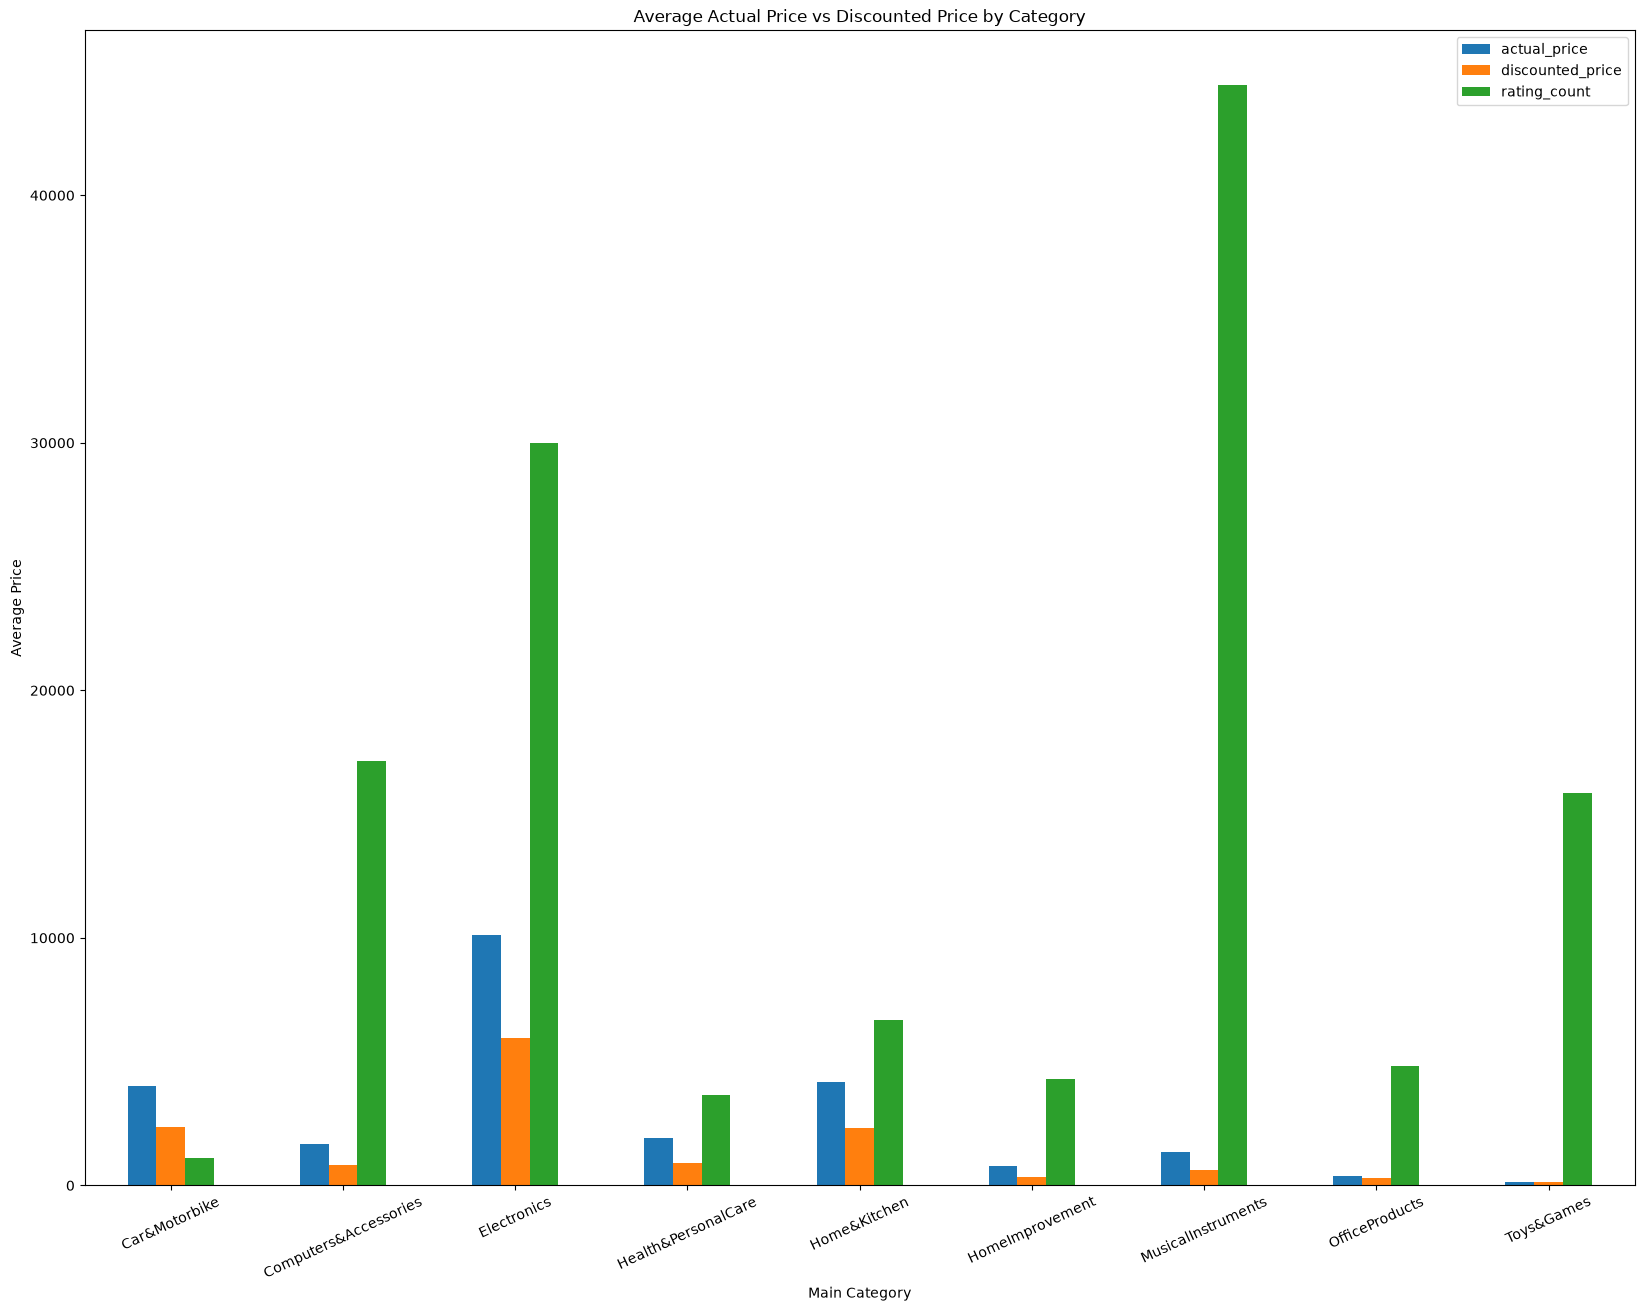

In [117]:
price_comparison.plot(
    kind='bar',
    figsize=(20,15)
)

plt.title('Average Actual Price vs Discounted Price by Category')
plt.xlabel('Main Category')
plt.ylabel('Average Price')
plt.xticks(rotation=25)
plt.show()

In [118]:
amazon_data.sort_values(
    'actual_price',
    ascending=True
).head(10)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,review_id,review_title,review_content,img_link,product_link,main_category
997,B00URH5E34,Inventis 5V 1.2W Portable Flexible USB LED Lig...,Computers&Accessories|Accessories&Peripherals|...,39.0,39.0,0.0,3.6,13572.0,The side the LED light falls on will depend on...,"R1NAJ7CT76Z9SF,R17L9205IYOD,R2GAKH6NBQPCFV,R12...","it worked properly for almost one year,ok,USB ...","very good product, very bright, easy to use, i...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Inventis-Portable-Flexib...,Computers&Accessories
975,B08TDJ5BVF,E-COSMOS 5V 1.2W Portable Flexible USB LED Lig...,Computers&Accessories|Accessories&Peripherals|...,39.0,39.0,0.0,3.8,3344.0,The side the LED light falls on will depend on...,"R3163MRJDEJMN7,RSQGCR6V7H766,R39PS8UO1CZS2D,R2...","Lighting,TINY & USEFUL.,Fair product,Worth for...","Recieved a wrong color.. But ok..,Simple and Q...",https://m.media-amazon.com/images/I/31s6OZfTO2...,https://www.amazon.in/COSMOS-Portable-Flexible...,Computers&Accessories
616,B07KCMR8D6,Classmate Octane Neon- Blue Gel Pens(Pack of 5...,OfficeProducts|OfficePaperProducts|Paper|Stati...,50.0,50.0,0.0,4.3,5792.0,5 vibrant Neon body color|Smooth and fast writ...,"RZAAQFY7BDSWC,R3604ZO2AA4PK5,R3C8K6Z6W9MDTQ,R3...","Nice ball pen,Good product,Average,Nice Pen,It...","Very nice ball pen,Thank you Amazon,Easy to ho...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Classmate-Octane-Neon-Pa...,OfficeProducts
710,B08TDJNM3G,E-COSMOS 5V 1.2W Portable Flexible USB LED Lig...,Computers&Accessories|Accessories&Peripherals|...,59.0,59.0,0.0,3.8,5958.0,"Portable, easy to use|LED lights for maximum i...","R3CEIRJ8YFRONO,R3ICE0RT3T14TH,R17764XIRZDB5H,R...","Good,Product as described,Good for the price,V...","Good,Product is as described, good we can use ...",https://m.media-amazon.com/images/I/413phG1P5U...,https://www.amazon.in/COSMOS-Portable-Flexible...,Computers&Accessories
811,B00P93X2H6,Classmate Pulse Spiral Notebook - 240 mm x 180...,OfficeProducts|OfficePaperProducts|Paper|Stati...,67.0,75.0,11.0,4.1,1269.0,The cover design of the notebook is subject to...,"R3QLOAFS794JE2,R3N8H6JX73IGQM,RR2G573NOMISE,R1...","it's nice. simple and easy.,It's good but I or...",I liked because it was aesthetically pleasing....,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Classmate-Pulse-Spiral-N...,OfficeProducts
1165,B0B4PPD89B,Kitchenwell 18Pc Plastic Food Snack Bag Pouch ...,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,79.0,79.0,0.0,4.0,97.0,Made in India !|Perfect for tightly sealing an...,"R2YLDT44YPDA2G,R39360RU5VF8V5,R17JJCUW7LT3JK,R...","Good clips.,Second quality,Value for money.,No...",I bought it for ₹79. Don't think that because ...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Kitchenwell-Plastic-Keep...,Home&Kitchen
1094,B08F47T4X5,VR 18 Pcs - 3 Different Size Plastic Food Snac...,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,89.0,89.0,0.0,4.2,19621.0,MULTI-PURPOSE: Can be used to seal all types o...,"R37CHVALZ1PLJG,R2DLNWVOG65T2N,R1OXPNJF31B34Y,R...","Very nice,Works as it should,Not the best but ...","Product is good and color full, completely liv...",https://m.media-amazon.com/images/I/51swXR+r2x...,https://www.amazon.in/VR-Pcs-Different-Multi-C...,Home&Kitchen
783,B09N6TTHT6,E-COSMOS Plug in LED Night Light Mini USB LED ...,Computers&Accessories|Accessories&Peripherals|...,89.0,99.0,10.0,4.2,241.0,Multi-purpose: you can use it as night sleepin...,"R1YVU5NMCJDX8M,R3MG5C14NRKOHR,R1T3DO26SFI3TL,R...","Good & attractive,Very versatile,Good,Good Pro...",Some USB ports are little loose but I will man...,https://m.media-amazon.com/images/I/318Gp3pIqX...,https://www.amazon.in/DASITON-Flexible-Ambient...,Computers&Accessories
854,B00VA7YYUO,Apsara Platinum Pencils Value Pack - Pack of 20,Home&Kitchen|CraftMaterials|Drawin

In [119]:
amazon_data.sort_values(
    'actual_price',
    ascending=False
)[['product_name', 'actual_price']].head(10)

,product_name,actual_price
249,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,139900.0
255,VU 164 cm (65 inches) The GloLED Series 4K Sma...,85000.0
283,LG 139 cm (55 inches) 4K Ultra HD Smart LED TV...,79990.0
1354,LG 1.5 Ton 5 Star AI DUAL Inverter Split AC (C...,75990.0
568,"Samsung Galaxy S20 FE 5G (Cloud Navy, 8GB RAM,...",74999.0
192,Samsung 138 cm (55 inches) Crystal 4K Neo Seri...,70900.0
325,OnePlus 163.8 cm (65 inches) U Series 4K LED S...,69999.0
332,MI 138.8 cm (55 inches) 5X Series 4K Ultra HD ...,69999.0
276,Samsung 138 cm (55 inches) Crystal 4K Series U...,69900.0
108,VU 139 cm (55 inches) The GloLED Series 4K Sma...,65000.0


# To 10 product having highest Actual value

In [120]:
amazon_data.sort_values(
    'actual_price',
    ascending=True
)[['product_name', 'actual_price']].head(10)

,product_name,actual_price
997,Inventis 5V 1.2W Portable Flexible USB LED Lig...,39.0
975,E-COSMOS 5V 1.2W Portable Flexible USB LED Lig...,39.0
616,Classmate Octane Neon- Blue Gel Pens(Pack of 5...,50.0
710,E-COSMOS 5V 1.2W Portable Flexible USB LED Lig...,59.0
811,Classmate Pulse Spiral Notebook - 240 mm x 180...,75.0
1165,Kitchenwell 18Pc Plastic Food Snack Bag Pouch ...,79.0
1094,VR 18 Pcs - 3 Different Size Plastic Food Snac...,89.0
783,E-COSMOS Plug in LED Night Light Mini USB LED ...,99.0
854,Apsara Platinum Pencils Value Pack - Pack of 20,99.0
808,BRUSTRO Copytinta Coloured Craft Paper A4 Size...,99.0


# Top 10 product having lowest actual value

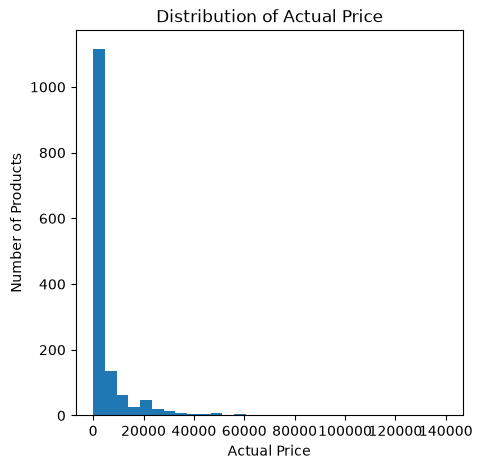

In [122]:
amazon_data['actual_price'].plot(
    kind='hist',
    bins=30,
    figsize=(5, 5)
)

plt.title('Distribution of Actual Price')
plt.xlabel('Actual Price')
plt.ylabel('Number of Products')
plt.show()

# we have more product in the range of 0 to 500 of Actual price, graph mostly lef side mein shifted hai means lower price 

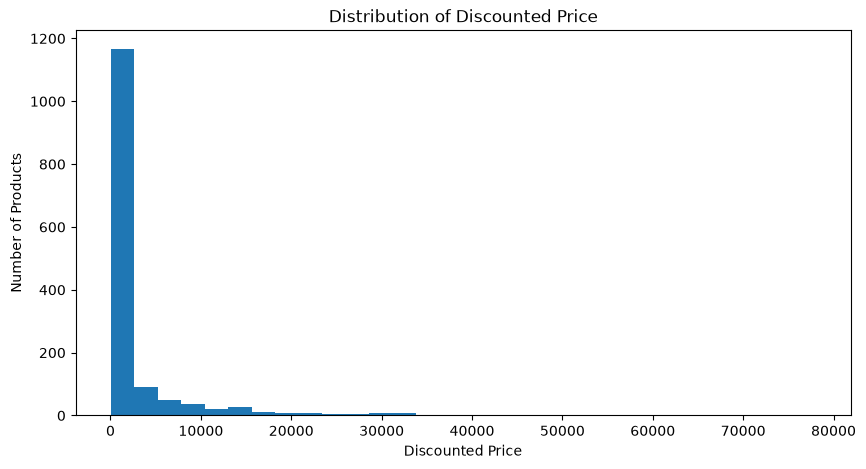

In [123]:
amazon_data['discounted_price'].plot(
    kind='hist',
    bins=30,
    figsize=(10, 5)
)

plt.title('Distribution of Discounted Price')
plt.xlabel('Discounted Price')
plt.ylabel('Number of Products')
plt.show()

#  Discounted price bhi left aligned hai

In [124]:
amazon_data['price_difference'] = (
    amazon_data['actual_price']
    - amazon_data['discounted_price']
)

In [126]:
amazon_data['price_difference'].mean()

np.float64(2319.6797610921503)

# Average difference between Actual price and Discounted prize is 2319 

In [127]:
amazon_data.sort_values(
    'discount_percentage',
    ascending=False
)[['product_name', 'discount_percentage']].head(10)

,product_name,discount_percentage
695,"rts [2 Pack] Mini USB C Type C Adapter Plug, T...",94.0
372,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",91.0
380,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",91.0
364,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",91.0
368,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",91.0
334,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",91.0
557,LAPSTER 12pcs Spiral Cable Protectors for Char...,90.0
920,"Silicone Rubber Earbuds Tips, Eartips, Earpads...",90.0
644,Sounce Spiral Charger Cable Protector Data Cab...,90.0
407,Sounce Spiral Charger Cable Protector Data Cab...,90.0


In [ ]:
# This product having highest discount

In [132]:
amazon_data.sort_values(
    'discount_percentage',
    ascending=True
)[['product_name', 'discount_percentage']].head(49)

,product_name,discount_percentage
1457,Philips HD9306/06 1.5-Litre Electric Kettle (M...,0.0
406,"OnePlus Nord 2T 5G (Jade Fog, 12GB RAM, 256GB ...",0.0
539,"LIRAMARK Webcam Cover Slide, Ultra Thin Laptop...",0.0
33,Samsung Original Type C to C Cable - 3.28 Feet...,0.0
1268,HUL Pureit Germkill kit for Advanced 23 L wate...,0.0
321,Mi 80 cm (32 inches) HD Ready Android Smart LE...,0.0
1304,Preethi MGA-502 0.4-Litre Grind and Store Jar ...,0.0
466,Samsung Ehs64 Ehs64Avfwecinu Hands-Free Wired ...,0.0
637,Casio FX-991ES Plus-2nd Edition Scientific Cal...,0.0
616,Classmate Octane Neon- Blue Gel Pens(Pack of 5...,0.0


# Discount on above project is zero

In [137]:
amazon_data['discount_amount'] = (
    amazon_data['actual_price'] -
    amazon_data['discounted_price']
)
amazon_data['discount_amount']

0        700.0
1        150.0
2       1700.0
3        370.0
4        245.0
         ...  
1460     540.0
1461     765.0
1462     861.0
1463     491.0
1464     827.0
Name: discount_amount, Length: 1465, dtype: float64

In [139]:
amazon_data['discount_amount'].mean()

np.float64(2319.6797610921503)

# Average saving on product

In [140]:
amazon_data.sort_values(
    'discount_amount',
    ascending=False
)[['product_name', 'actual_price', 'discounted_price', 'discount_amount']].head(10)

,product_name,actual_price,discounted_price,discount_amount
249,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,139900.0,77990.0,61910.0
1182,"Coway Professional Air Purifier for Home, Long...",59900.0,14400.0,45500.0
568,"Samsung Galaxy S20 FE 5G (Cloud Navy, 8GB RAM,...",74999.0,37990.0,37009.0
150,VU 138 cm (55 inches) Premium Series 4K Ultra ...,65000.0,29990.0,35010.0
1354,LG 1.5 Ton 5 Star AI DUAL Inverter Split AC (C...,75990.0,42990.0,33000.0
1306,ECOVACS DEEBOT N8 2-in-1 Robotic Vacuum Cleane...,59900.0,27900.0,32000.0
283,LG 139 cm (55 inches) 4K Ultra HD Smart LED TV...,79990.0,47990.0,32000.0
255,VU 164 cm (65 inches) The GloLED Series 4K Sma...,85000.0,54990.0,30010.0
108,VU 139 cm (55 inches) The GloLED Series 4K Sma...,65000.0,37999.0,27001.0
323,TCL 108 cm (43 inches) 4K Ultra HD Certified A...,51990.0,24990.0,27000.0


# Topmost 10 product for maximum savings

In [142]:
amazon_data.sort_values(
    'discount_amount',
    ascending=True
)[['product_name', 'actual_price', 'discounted_price', 'discount_amount']].head(49)

,product_name,actual_price,discounted_price,discount_amount
887,"Camel Artist Acrylic Color Box - 9ml Tubes, 12...",310.0,310.0,0.0
924,Faber-Castell Connector Pen Set - Pack of 25 (...,150.0,150.0,0.0
1161,"PHILIPS HL1655/00 Hand Blender, White Jar 250W",1695.0,1695.0,0.0
1165,Kitchenwell 18Pc Plastic Food Snack Bag Pouch ...,79.0,79.0,0.0
406,"OnePlus Nord 2T 5G (Jade Fog, 12GB RAM, 256GB ...",33999.0,33999.0,0.0
1181,Bajaj ATX 4 750-Watt Pop-up Toaster (White),1499.0,1499.0,0.0
757,"Parker Quink Ink Bottle, Blue",100.0,100.0,0.0
850,"Pentonic Multicolor Ball Point Pen, Pack of 10",120.0,120.0,0.0
1222,Kitchenwell Multipurpose Portable Electronic D...,239.0,239.0,0.0
466,Samsung Ehs64 Ehs64Avfwecinu Hands-Free Wired ...,499.0,499.0,0.0


# On above product our saving is zero

In [143]:
amazon_data.groupby('main_category')['discount_amount'].mean().sort_values(
    ascending=False
)

main_category
Electronics              4161.423954
Home&Kitchen             1831.458013
Car&Motorbike            1661.000000
Health&PersonalCare      1001.000000
Computers&Accessories     840.972759
MusicalInstruments        709.000000
HomeImprovement           462.000000
OfficeProducts             95.612903
Toys&Games                  0.000000
Name: discount_amount, dtype: float64

# Category wise average saving

In [144]:
amazon_data['discount_amount'].sum()

np.float64(3398330.85)

# This is the sum of total savings on all types of category

In [146]:
amazon_data['saving_percentage'] = (
    amazon_data['discount_amount']
    / amazon_data['actual_price']
) * 100

amazon_data['saving_percentage']

0       63.694268
1       42.979943
2       89.520800
3       52.932761
4       61.403509
          ...    
1460    58.759521
1461    25.123153
1462    27.954545
1463    25.978836
1464    22.411924
Name: saving_percentage, Length: 1465, dtype: float64

# Saving percentage on individual products

In [147]:
amazon_data['saving_percentage'].mean()

np.float64(47.68492433489038)

# Average Saving percent